# **Linear Regression**


Linear Regression is a method to find a relationship between input variables (features) and an output variable (target).

***Importing Basic Libraries***

In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**How can we load it in Python using pandas and see the first few rows?**.

In [76]:
df = pd.read_csv('dataset/Food_Delivery_Times.csv')
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


## Exploring the Data**

Check your dataset by some of the commands to quickly see its size, column names, missing values, and basic statistics.

In [77]:
df.shape

(1000, 9)

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [79]:
df.describe()


,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


In [80]:
df.isnull().sum()

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

### Handling Null Values
Fill the missing values in the categorical columns by replacing them with the most frequent value in each column.

In [81]:
cat_col = ['Weather','Traffic_Level','Time_of_Day']
for col in cat_col:
    df[col] = df[col].fillna(df[col].mode()[0])



<Axes: xlabel='Courier_Experience_yrs', ylabel='Density'>

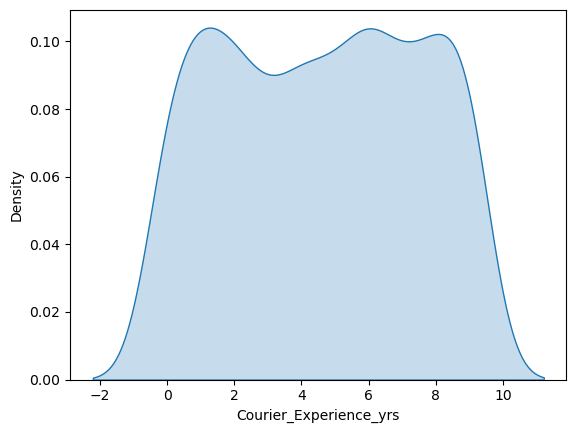

In [82]:
sns.kdeplot(df['Courier_Experience_yrs'],fill = True)
#we check distribution to check skeness if skewness is present then we use median if not then mean


In [83]:
#no skewness present (no outliers) then mean
df['Courier_Experience_yrs'] = df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].mean())

In [84]:
df.isnull().sum()

Order_ID                  0
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64

## Visualizing the Data
Visualize the relationships between all pairs of variables in the dataset to see patterns and correlations.

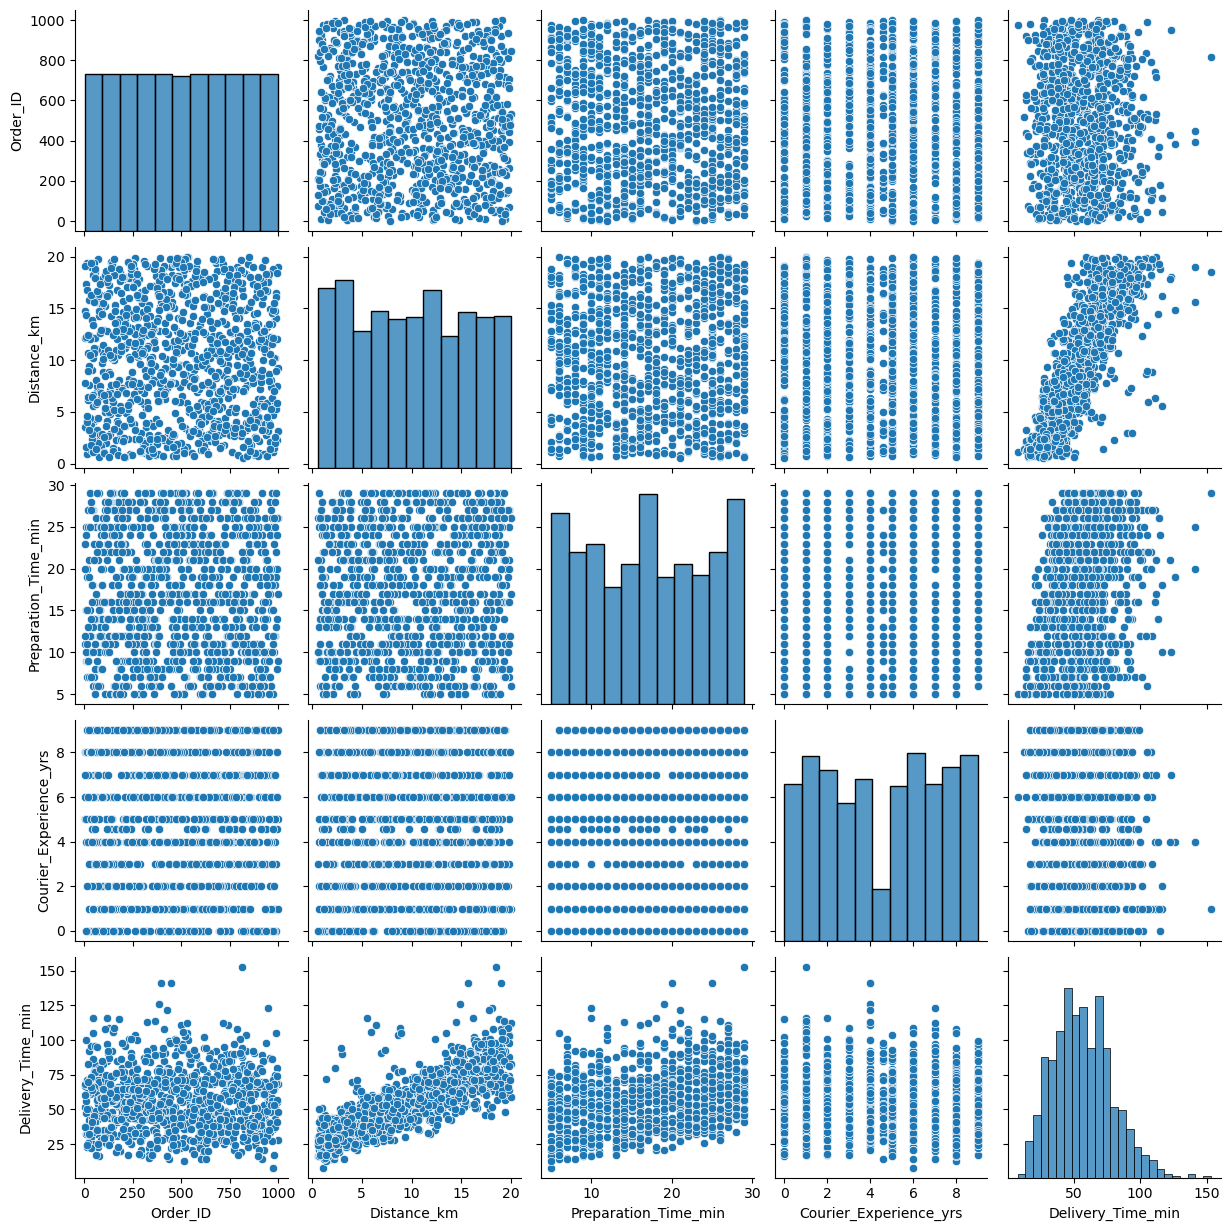

In [85]:
sns.pairplot(df)

### Mapping Values
Linear Regression works only on numeric data, so we need to convert categorical columns into numbers.

In [86]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
encoder

LabelEncoder()

In [ ]:
#label encoding
df_copy = df.copy()
cat_cols = ['Weather','Traffic_Level','Time_of_Day','Vehicle_Type']
for col in cat_cols:
    df[col] = encoder.fit_transform(df[col].astype(str))
df.head()



,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,4,1,0,2,12,1.0,43
1,738,16.42,0,2,1,0,20,2.0,84
2,741,9.52,1,1,3,2,28,1.0,59
3,661,7.44,2,2,0,2,5,1.0,37
4,412,19.03,0,1,2,0,16,5.0,68


In [ ]:
#onehot encoding
df_dummies = pd.get_dummies(df_copy, columns=['Weather','Traffic_Level','Time_of_Day','Vehicle_Type'])
df_dummies = df_dummies.astype(int)
df_dummies

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Weather_Clear,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy,Traffic_Level_High,Traffic_Level_Low,Traffic_Level_Medium,Time_of_Day_Afternoon,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Vehicle_Type_Bike,Vehicle_Type_Car,Vehicle_Type_Scooter
0,522,7,12,1,43,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1
1,738,16,20,2,84,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0
2,741,9,28,1,59,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1
3,661,7,5,1,37,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1
4,412,19,16,5,68,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,107,8,13,3,54,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0
996,271,16,8,9,71,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1
997,861,15,26,2,81,0,0,0,1,0,1,0,0,0,1,0,0,0,0,1
998,436,14,8,0,55,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0


## **Defining Features and Target**

X (features) → known factors (distance, traffic, weather, etc.)

y (target) → what we want to predict (delivery time)


In [89]:
X_encoded = df.drop("Delivery_Time_min",axis=1)
y_encoded =df['Delivery_Time_min']
X_dumies = df_dummies.drop("Delivery_Time_min", axis=1)
y_dumies = df_dummies['Delivery_Time_min']

## Splitting Data into Train and Test Sets**

How can we check how well our model performs on unseen data?
Why do we split the dataset into two parts:

Training set (80%) → used to train the model

Testing set (20%) → used to evaluate the modelbrary.


In [90]:
from sklearn.model_selection import train_test_split


In [91]:
x_en_train, x_en_test, y_en_train, y_en_test = train_test_split(X_encoded, y_encoded, test_size=0.2, random_state=42)
x_dm_train, x_dm_test, y_dm_train, y_dm_test = train_test_split(X_dumies,y_dumies, test_size=0.2, random_state=42)


In [92]:
from sklearn.linear_model import LinearRegression


In [93]:
model1 = LinearRegression()
model

LinearRegression()

In [94]:
model1.fit(x_en_train, y_en_train)


LinearRegression()

In [95]:
model2 = LinearRegression()
model2.fit(x_dm_train,y_dm_train)

LinearRegression()

## Training the Linear Regression Model**


## Making Predictions

Use the trained model to predict delivery times for the test data.

In [96]:
y_pred1 = model1.predict(x_en_test)
y_pred2 = model2.predict(x_dm_test)

## **Evaluating the Model**

Check how accurate your predictions are by calculating the average error, squared error, and R² score.


In [99]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
mse1 = mean_squared_error(y_en_test,y_pred1)
mse2 = mean_squared_error(y_dm_test,y_pred2)
mae1 = mean_absolute_error(y_en_test,y_pred1)
mae2 = mean_squared_error(y_dm_test,y_pred2)
score1 = r2_score(y_en_test,y_pred1)
score2 = r2_score(y_dm_test,y_pred2)

print(f'model1 evaluation results:\nMSE: {mse1}\nMAE: {mae1}\nsquare: {score1}')
print(f'model2 evaluation results:\nMSE: {mse2}\nMAE: {mae2}\nsquare: {score2}')

model1 evaluation results:
MSE: 109.20229935083353
MAE: 7.28610280466938
square: 0.7563683012365922
model2 evaluation results:
MSE: 81.23130526252949
MAE: 81.23130526252949
square: 0.818771939679602


In [101]:
#adjusted R^2
adjr1 = 1 - (1-score1)*(df.shape[0]-1)/(df.shape[0]-df.shape[1]-1)
adjr2 = 1 - (1-score2)*(df_dummies.shape[0]-1)/(df_dummies.shape[0]-df_dummies.shape[1]-1)
print(f'For model1 :{adjr1}\nFor model2 :{adjr2}')


For model1 :0.7541534676114703
For model2 :0.8150696299692772


### **Visualizing Predictions**


Create a scatter plot to compare actual vs predicted delivery times and visually check how well the model is performing.


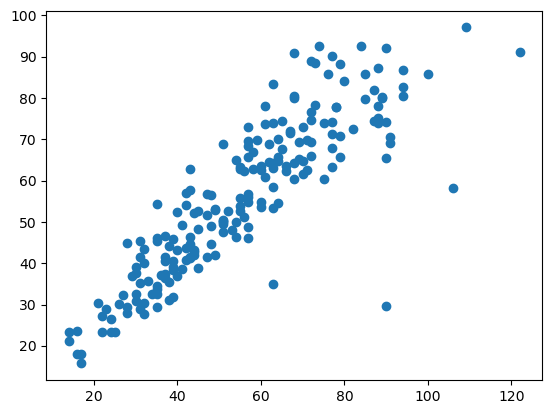

In [103]:
plt.scatter(y_en_test,y_pred1)

### Ridge Regression
Train a Ridge regression model on the training data, predict delivery times for the test set, and evaluate its accuracy using MAE, MSE, and R².

### Lasso Regression
Train a Lasso regression model on your training data, predict delivery times for the test set, and check how accurate the predictions are using MAE, MSE, and R².

### Polynomial Regression
Transform your features to include polynomial terms, train a Linear Regression model on them, and calculate the mean squared error to see how well the curved model fits your data.

# Conclusion
-Predicted food delivery times using features like distance, traffic, weather, time, and courier experience.

-Applied Linear Regression for basic predictions.

-Used Ridge and Lasso to reduce overfitting and improve accuracy.

-Explored Polynomial Regression to capture nonlinear relationships.

-Evaluated models with MAE, MSE, and R² to measure performance.

-Demonstrated a real-world application of regression in optimizing delivery operations.